# Week 4: Backpropagation in your FiveM world
**Based on slide 39 and the continuation on slides 40–43 of Week 4 session 1.**

We recreate the lecturer's NumPy XOR exercise: **2 input neurons → 4 hidden neurons → 1 output neuron**, sigmoid activation, 10,000 epochs and learning rate 0.1.

Our fictional `tqv_lootlocker` checks whether a player carries **exactly one** of two keycards. Carrying both creates a security conflict. This is an invented gameplay rule chosen to match XOR, not a real ox_inventory restriction.

This notebook runs in Python outside FiveM. It needs no server, Qbox or ox_inventory installation. All data is synthetic.

## 1. Run it in Anaconda
Open this file in Jupyter Notebook or JupyterLab, select a Python 3 kernel, and choose **Run All**. You need NumPy and Matplotlib. If an import fails, run `%pip install numpy matplotlib` in a new cell, then restart the kernel.

| Python idea | FiveM analogy |
|---|---|
| Input `X` | Two item-presence flags collected from inventory |
| Target `y` | The correct locker decision supplied during training |
| Weights | Adjustable importance of each connection |
| Bias | A learned offset for each neuron |
| Forward pass | Calculate the current prediction |
| Backpropagation | Calculate how each parameter affects the error |
| Parameter update | Change weights and biases using those gradients |

Unlike a manually edited Lua config, weights and biases change automatically during training.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Keep displayed numbers readable. The model still uses full precision.
np.set_printoptions(precision=4, suppress=True)

## 2. Training data: the XOR rule
Each row represents one inventory state. Column 0 is the red keycard and column 1 is the blue keycard. `1` means present, `0` means absent.

| Red | Blue | Open locker? |
|---|---|---|
| 0 | 0 | 0: no keycard |
| 0 | 1 | 1: blue only |
| 1 | 0 | 1: red only |
| 1 | 1 | 0: conflicting keycards |

XOR cannot be separated by one straight decision boundary. The hidden layer with a nonlinear activation lets this network learn it.

In [2]:
# X shape: (4 inventory states, 2 input features).
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)

# y shape: (4 inventory states, 1 expected output).
y = np.array([[0], [1], [1], [0]], dtype=float)

print("Inputs:\n", X)
print("Correct decisions:\n", y)

Inputs:
 [[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
Correct decisions:
 [[0.]
 [1.]
 [1.]
 [0.]]


## 3. Neural network: slides 39–42
For each layer, calculate `z = inputs @ weights + bias`, then apply sigmoid: `1 / (1 + exp(-z))`.

The sigmoid derivative below accepts an **already activated value**, so it calculates `a * (1 - a)`.

We keep the slides' update convention: `error = target - prediction`, then **add** the correction. This is equivalent to descending the sum of half-squared errors. We report mean squared error (MSE) for readability, as the slides do. An implementation that differentiates MSE directly includes a scaling factor, so its learning rate may need adjusting.

In [3]:
class NeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size, seed=42):
        # A fixed seed makes this lesson reproducible when you restart the kernel.
        rng = np.random.default_rng(seed)
        self.weights_input_hidden = rng.standard_normal((input_size, hidden_size))
        self.weights_hidden_output = rng.standard_normal((hidden_size, output_size))
        self.bias_hidden = np.zeros((1, hidden_size))
        self.bias_output = np.zeros((1, output_size))

    @staticmethod
    def sigmoid(x):
        # Clipping avoids overflow in exp for very large values.
        return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

    @staticmethod
    def sigmoid_derivative(activated_value):
        return activated_value * (1 - activated_value)

    def feedforward(self, X):
        # (N, 2) @ (2, 4) + (1, 4) produces (N, 4).
        self.hidden_activation = X @ self.weights_input_hidden + self.bias_hidden
        self.hidden_output = self.sigmoid(self.hidden_activation)

        # (N, 4) @ (4, 1) + (1, 1) produces (N, 1).
        self.output_activation = self.hidden_output @ self.weights_hidden_output + self.bias_output
        self.predicted_output = self.sigmoid(self.output_activation)
        return self.predicted_output

    def backward(self, X, y, learning_rate):
        # Compare our locker prediction with the known correct decision.
        output_error = y - self.predicted_output
        output_delta = output_error * self.sigmoid_derivative(self.predicted_output)

        # Use the current output weights BEFORE updating them.
        # The chain rule carries the output correction back to hidden neurons.
        hidden_error = output_delta @ self.weights_hidden_output.T
        hidden_delta = hidden_error * self.sigmoid_derivative(self.hidden_output)

        # Combine corrections from every training row and update parameters.
        self.weights_hidden_output += learning_rate * (self.hidden_output.T @ output_delta)
        self.bias_output += learning_rate * np.sum(output_delta, axis=0, keepdims=True)
        self.weights_input_hidden += learning_rate * (X.T @ hidden_delta)
        self.bias_hidden += learning_rate * np.sum(hidden_delta, axis=0, keepdims=True)

    def train(self, X, y, epochs=10000, learning_rate=0.1):
        # Record the initial loss, then the loss after each update.
        losses = [float(np.mean((y - self.feedforward(X)) ** 2))]
        for epoch in range(1, epochs + 1):
            self.feedforward(X)
            self.backward(X, y, learning_rate)
            loss = float(np.mean((y - self.feedforward(X)) ** 2))
            losses.append(loss)
            if epoch == 1 or epoch % 2000 == 0:
                print(f"Epoch {epoch:5d} | MSE: {loss:.6f}")
        return np.array(losses)

## 4. Train the network
An **epoch** visits the entire dataset once. We use all four rows together as one **batch**, giving one parameter-update **iteration** per epoch. Therefore, 10,000 epochs here means 10,000 updates. This relationship changes if you split the data into smaller batches.

In [4]:
# Recreating the model here lets you rerun training from the same starting point.
nn = NeuralNetwork(input_size=2, hidden_size=4, output_size=1, seed=42)
before_training = nn.feedforward(X).copy()
loss_history = nn.train(X, y, epochs=10000, learning_rate=0.1)
after_training = nn.feedforward(X).copy()

Epoch     1 | MSE: 0.275201
Epoch  2000 | MSE: 0.157595
Epoch  4000 | MSE: 0.035783
Epoch  6000 | MSE: 0.008346
Epoch  8000 | MSE: 0.004010
Epoch 10000 | MSE: 0.002507


Initial MSE: 0.277470
Final MSE:   0.002507


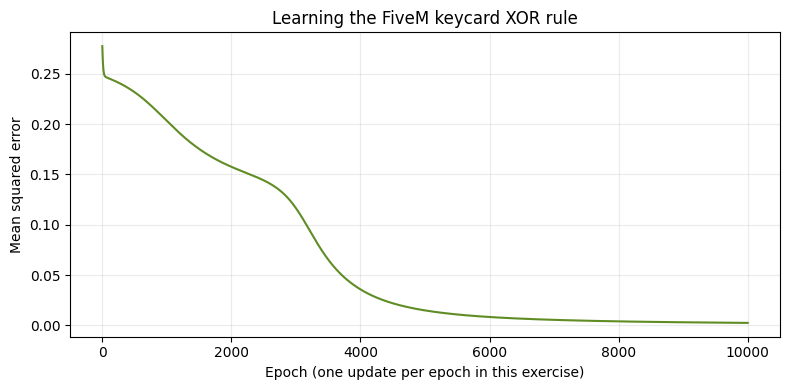

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history, color="#608c24")
plt.xlabel("Epoch (one update per epoch in this exercise)")
plt.ylabel("Mean squared error")
plt.title("Learning the FiveM keycard XOR rule")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Initial MSE: {loss_history[0]:.6f}")
print(f"Final MSE:   {loss_history[-1]:.6f}")

## 5. Test the decisions: slide 43
Use `0.5` as the classification threshold. A sigmoid value is a model score between 0 and 1. It is **not automatically a calibrated probability**, so a score of 0.87 does not by itself establish an 87% chance of anything.

We test the four training combinations to confirm that the network learned XOR. Because these are the same states used during training, this is not evidence of generalisation to real player data.

In [6]:
decisions = (after_training >= 0.5).astype(int)
print("Red Blue | Target | Before | After  | Decision")
for inventory, target, old, new, decision in zip(X, y, before_training, after_training, decisions):
    print(f" {int(inventory[0])}    {int(inventory[1])}  |   {int(target[0])}    | {old[0]:.4f} | {new[0]:.4f} | {int(decision[0])}")

accuracy = np.mean(decisions == y)
print(f"Accuracy on the four XOR states: {accuracy:.0%}")
assert np.array_equal(decisions, y.astype(int)), "Try a different seed or more epochs."
assert loss_history[-1] < loss_history[0], "Training did not reduce the loss."

Red Blue | Target | Before | After  | Decision
 0    0  |   0    | 0.5972 | 0.0318 | 0
 0    1  |   1    | 0.6482 | 0.9472 | 1
 1    0  |   1    | 0.7159 | 0.9516 | 1
 1    1  |   0    | 0.7408 | 0.0623 | 0
Accuracy on the four XOR states: 100%


## 6. Try one player's inventory
Change the two flags below and run this cell. Only binary item-presence flags belong to this exercise. Item quantities, movement speed or headshot ratio would be different features requiring a new dataset and task.

In [7]:
has_red_keycard = True
has_blue_keycard = False

# Convert Lua-style boolean inventory checks into a single Python input row.
player_input = np.array([[int(has_red_keycard), int(has_blue_keycard)]], dtype=float)
score = float(nn.feedforward(player_input)[0, 0])
print(f"Model score: {score:.4f}")
print("OPEN LOCKER" if score >= 0.5 else "KEEP LOCKER CLOSED")

Model score: 0.9516
OPEN LOCKER


## 7. How the same rule looks in FiveM Lua
This is an analogy only. The Python model is not connected to FiveM. For an actual fixed gameplay rule, enforce the rule on the server with ordinary code. Your server's inventory integration supplies these booleans.

```lua
-- Booleans obtained from your server-side inventory checks.
local hasRedKeycard = true
local hasBlueKeycard = false

-- Lua ~= acts as XOR when both operands are booleans.
local canOpenLocker = hasRedKeycard ~= hasBlueKeycard
```

The ANN exercise teaches how a network learns that rule from labelled examples. No anticheat claims, bans or real player records are involved.

## 8. Small experiments
1. Change `hidden_size=4` to `hidden_size=1`, recreate the model, and rerun training. Can it learn all four decisions?
2. Change the learning rate from `0.1` to `0.01`. Compare the final loss after 10,000 epochs.
3. Change the seed. Compare the starting predictions and convergence.
4. Change the target for `[1, 1]` to `1`. You are now teaching OR instead of XOR. Explain the changed gameplay rule.

**Remember:** forward pass predicts, loss measures error, backpropagation calculates parameter gradients, and the update changes the parameters. Hidden neurons learn numerical combinations. We do not assign them fixed meanings such as “red-keycard detector”.